In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

DATA_DIR = Path(r"D:\F20DL CW UG\Insurance-Fraud-Detection\Insurance-Fraud-Detection")
RESULTS = Path("../results/images")

CLASSES = ["Fraud", "Non-Fraud"]

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

tf.keras.utils.set_random_seed(SEED) # Sets the random seed for TensorFlow (reproducibility of results)

print("TensorFlow version:", tf.__version__)
print("Dataset found:", DATA_DIR.exists())
print("GPU available:", tf.config.list_physical_devices("GPU")) # checks whether TensorFlow can use graphics card to train faster

TensorFlow version: 2.21.0
Dataset found: True
GPU available: []


In [2]:
from sklearn.model_selection import train_test_split

## Function to list all image files in a given folder
def list_images(folder):
    files = []
    for f in folder.iterdir(): # loops over all files in folder
        if f.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            files.append(str(f))
    return files

# Function to get the paths and labels of images in a given split (train/test)
def get_paths_and_labels(split):
    paths = []
    labels = []
    for c in CLASSES: 
        files = list_images(DATA_DIR / split / c) #
        paths += files
        if c == "Fraud":
            labels += [1] * len(files) # adds a label of 1 for each fraud image
        else:
            labels += [0] * len(files) # adds a label of 0 for each non-fraud image
    return paths, labels

train_paths, train_labels = get_paths_and_labels("train") # gets the paths and labels for the training set
test_paths, test_labels = get_paths_and_labels("test") # gets the paths and labels for the test set

# Splits the training set into a training and validation set
train_paths, val_paths, train_labels, val_labels = train_test_split(
    train_paths, train_labels,
    test_size=0.15, # 15% of the training data will be used for validation
    stratify=train_labels, # ensures the same proportion of fraud and non-fraud images in both sets
    random_state=SEED # sets the random seed for reproducibility
)

# Prints the number of images and fraud cases in each set
print("Train:     ", len(train_paths), "images,", sum(train_labels), "fraud")
print("Validation:", len(val_paths), "images,", sum(val_labels), "fraud")
print("Test:      ", len(test_paths), "images,", sum(test_labels), "fraud")

Train:      4420 images, 170 fraud
Validation: 780 images, 30 fraud
Test:       1416 images, 93 fraud


In [3]:
# Function to load and resize an image given its path and label
def load_and_resize(path, label):
    img = tf.io.read_file(path) # Read the image file
    img = tf.io.decode_image(img, channels=3, expand_animations=False) # Decode the image
    img = tf.image.resize(img, IMG_SIZE) # Resize the image
    img = tf.cast(img, tf.uint8) # Cast the image to uint8
    return img, label

# Function to normalise an image given its label
def normalise(img, label):
    img = tf.cast(img, tf.float32) / 255.0 # Normalise the image to [0, 1]
    return img, label

# Function to create a TensorFlow dataset from image paths and labels
def make_dataset(paths, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels)) # creates a dataset
    ds = ds.map(load_and_resize, num_parallel_calls=tf.data.AUTOTUNE) # applies the load_and_resize function in parallel
    ds = ds.cache() # caches the dataset in memory for faster access

    # If shuffle is True, shuffle the dataset with a buffer size equal to the number of paths
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED) 
    ds = ds.map(normalise) 
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_paths, train_labels, shuffle=True) # creates the training dataset
val_ds = make_dataset(val_paths, val_labels) # creates the validation dataset
test_ds = make_dataset(test_paths, test_labels) # creates the test dataset

# Prints the shape of one batch of images and labels, and the range of pixel values
images, labels = next(iter(train_ds))
print("One batch of images:", images.shape)
print("One batch of labels:", labels.shape)
print("Pixel values from", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))

One batch of images: (32, 128, 128, 3)
One batch of labels: (32,)
Pixel values from 0.0 to 1.0


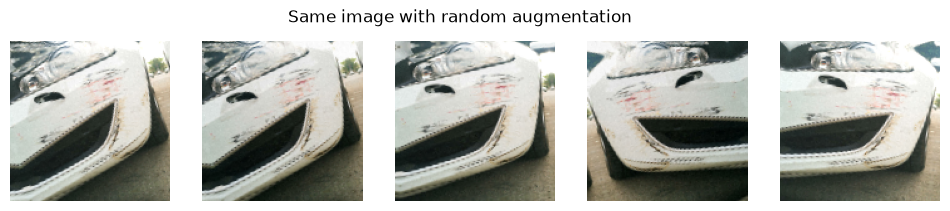

Class weights: {0: 0.52, 1: 13.0}


In [4]:
from tensorflow.keras import layers

# Data augmentation pipeline using Keras Sequential API
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"), # randomly flips the image horizontally
    layers.RandomRotation(0.05), # randomly rotates the image by up to 5% of 360 degrees
    layers.RandomBrightness(0.1, value_range=(0, 1)), # randomly adjusts the brightness of the image by up to 10%
], name="augmentation")

sample_img = images[0] # Select a sample image from the dataset
plt.figure(figsize=(12, 2.3)) # Create a figure with a specific size
for i in range(5): # Loop to create 5 augmented versions of the sample image
    aug = data_augmentation(tf.expand_dims(sample_img, 0), training=True) # Applies augmentation
    plt.subplot(1, 5, i + 1) # Create a subplot for each augmented image
    plt.imshow(aug[0]) 
    plt.axis("off")
plt.suptitle("Same image with random augmentation") 
plt.savefig(RESULTS / "augmentation_examples.png", dpi=150, bbox_inches="tight")
plt.show()

# Calculate class weights to handle class imbalance
n_total = len(train_labels)
n_fraud = sum(train_labels)
n_non_fraud = n_total - n_fraud
class_weight = {  # calculates the class weights for the two classes (0: non-fraud, 1: fraud)
    0: n_total / (2 * n_non_fraud),
    1: n_total / (2 * n_fraud),
}
print("Class weights:", class_weight)

In [5]:
from tensorflow.keras import models

# Function to build a CNN model
def build_cnn(filters=[32, 64, 128], dense_units=64, dropout=0.3, name="fraud_detection_cnn_v1"):
    model = models.Sequential(name=name) 
    model.add(layers.Input(shape=IMG_SIZE + (3,))) # Input layer
    model.add(data_augmentation)

    # Adds convolutional layers with specified filters, batch normalization, and max pooling
    for f in filters:
        model.add(layers.Conv2D(f, 3, padding="same", activation="relu"))
        model.add(layers.BatchNormalization())
        model.add(layers.MaxPooling2D())

    # Adds global average pooling, dense, and dropout layers
    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dense(dense_units, activation="relu"))
    model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    return model

# Build the CNN model and print its summary
model = build_cnn()
model.summary()

Model: "fraud_detection_cnn_v1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,465 (400.25 KB)

 Trainable params: 102,017 (398.50 KB)

 Non-trainable params: 448 (1.75 KB)

In [6]:
# Compiles the model with Adam optimizer, binary crossentropy loss, and metrics for precision, recall, and PR AUC
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), # Adam optimizer with a learning rate of 0.001
    loss="binary_crossentropy", #
    metrics=[
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(curve="PR", name="pr_auc"),
    ],
)

# Sets up early stopping to monitor validation PR AUC and stop training if it doesn't improve for 5 epochs
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=5,
    restore_best_weights=True,
)

# Trains the model using the training dataset, validation dataset, class weights, and early stopping
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30, # Number of epochs to train the model
    class_weight=class_weight,
    callbacks=[early_stop],
)

# Saves the trained model to the specified directory
MODELS = Path("../models")
MODELS.mkdir(exist_ok=True)
model.save(MODELS / "fraud_detection_cnn_v1.keras")

Epoch 1/30


d:\F20DL CW UG\f20dl-vehicle-fraud-ug-group9\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


139/139 ━━━━━━━━━━━━━━━━━━━━ 71s 494ms/step - loss: 0.7756 - pr_auc: 0.0567 - precision: 0.0500 - recall: 0.5294 - val_loss: 0.2805 - val_pr_auc: 0.0865 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 67s 478ms/step - loss: 0.6605 - pr_auc: 0.0876 - precision: 0.0624 - recall: 0.6471 - val_loss: 0.3937 - val_pr_auc: 0.0404 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 66s 476ms/step - loss: 0.6558 - pr_auc: 0.0728 - precision: 0.0660 - recall: 0.6588 - val_loss: 0.3443 - val_pr_auc: 0.1092 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 65s 470ms/step - loss: 0.6813 - pr_auc: 0.0710 - precision: 0.0595 - recall: 0.5882 - val_loss: 0.6046 - val_pr_auc: 0.0862 - val_precision: 0.0702 - val_recall: 0.5333
Epoch 5/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 65s 465ms/step - loss: 0.6417 - pr_auc: 0.0954 - precision: 0.0645 - recall: 0.7059 - val_loss: 1.1183 - val_pr

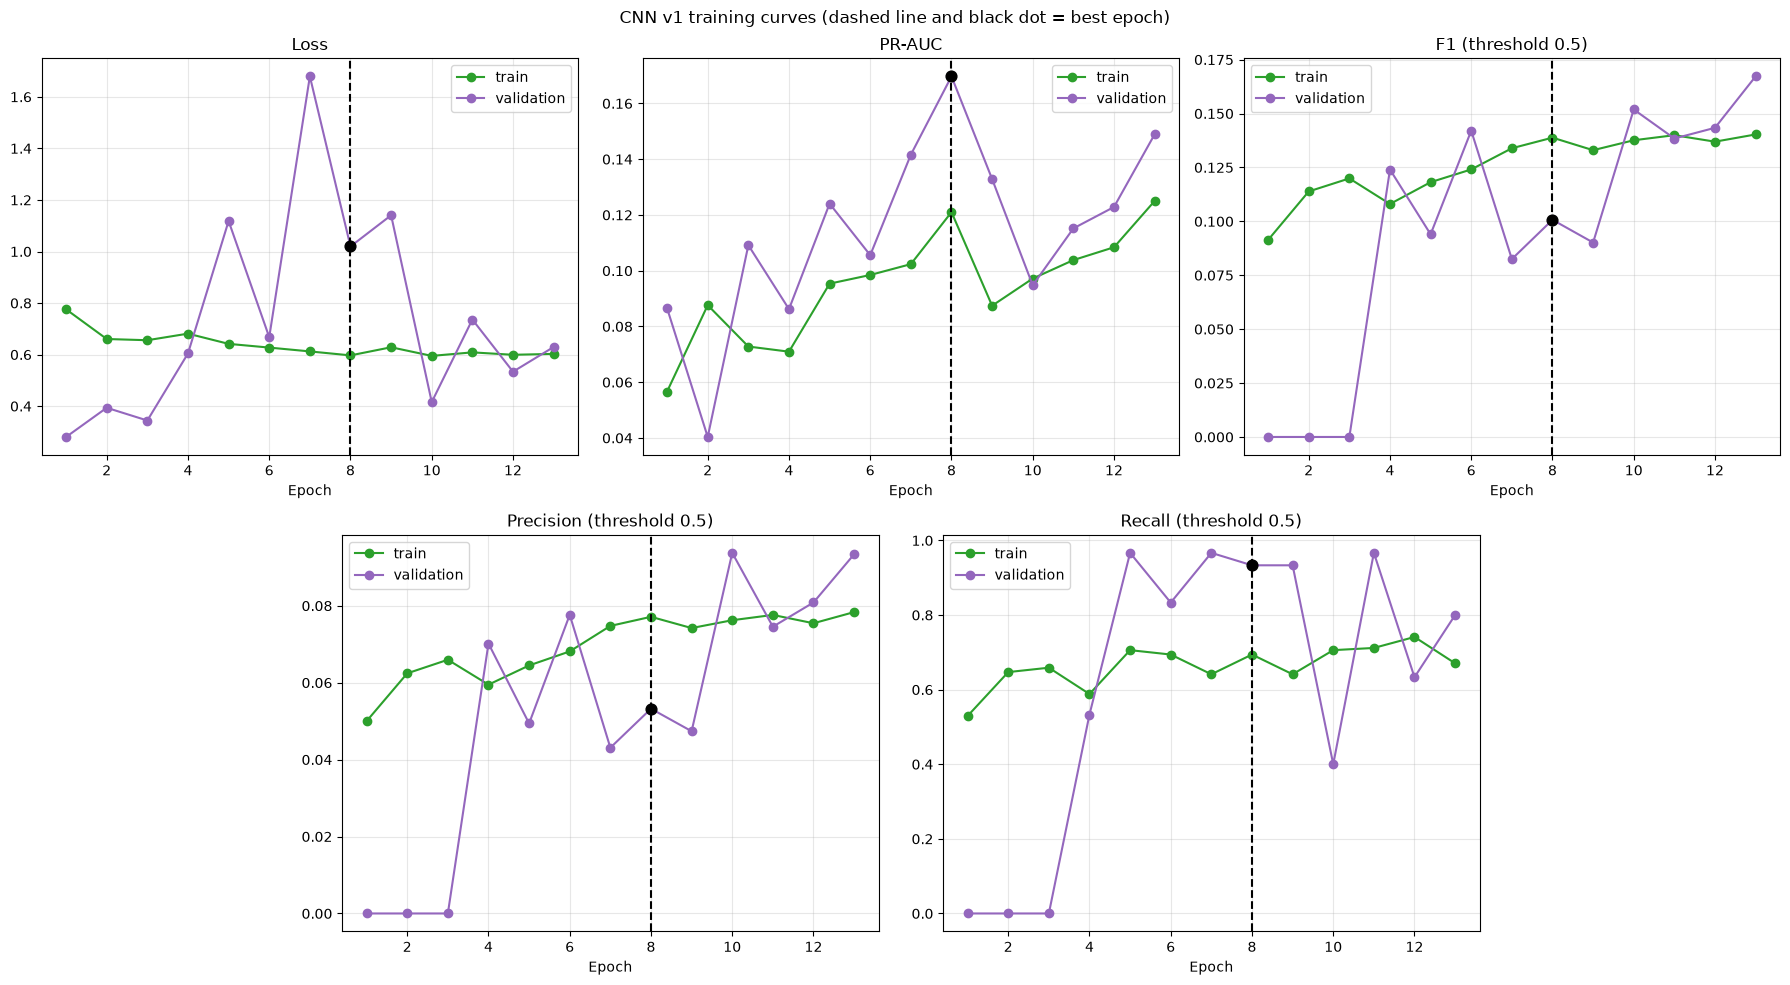

Best epoch: 8 | val PR-AUC: 0.1697


In [17]:
# Plots the training curves for loss, PR-AUC, F1, precision and recall over epochs
hist = history.history
epochs_run = range(1, len(hist["loss"]) + 1)

# Calculates F1 for each epoch from precision and recall
def f1_from(p, r):
    f1 = []
    for i in range(len(p)):
        if p[i] + r[i] == 0:
            f1.append(0)
        else:
            f1.append(2 * p[i] * r[i] / (p[i] + r[i]))
    return f1

hist["f1"] = f1_from(hist["precision"], hist["recall"])
hist["val_f1"] = f1_from(hist["val_precision"], hist["val_recall"])

metrics = ["loss", "pr_auc", "f1", "precision", "recall"]
titles = ["Loss", "PR-AUC", "F1 (threshold 0.5)", "Precision (threshold 0.5)", "Recall (threshold 0.5)"]

best_epoch = np.argmax(hist["val_pr_auc"]) + 1 # Finds the epoch with the highest validation PR-AUC

# Creates subplots for loss, PR AUC, F1 score, precision, and recall
fig = plt.figure(figsize=(18, 10))
grid = fig.add_gridspec(2, 6)
axes = [
    fig.add_subplot(grid[0, 0:2]),
    fig.add_subplot(grid[0, 2:4]),
    fig.add_subplot(grid[0, 4:6]),
    fig.add_subplot(grid[1, 1:3]),
    fig.add_subplot(grid[1, 3:5]),
]
for ax, metric, title in zip(axes, metrics, titles):
    ax.plot(epochs_run, hist[metric], label="train", color="tab:green", marker="o")
    ax.plot(epochs_run, hist["val_" + metric], label="validation", color="tab:purple", marker="o")
    ax.axvline(best_epoch, color="black", linestyle="--")
    ax.scatter(best_epoch, hist["val_" + metric][best_epoch - 1], color="black", s=60, zorder=3)
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("CNN v1 training curves (dashed line and black dot = best epoch)")
plt.tight_layout()
plt.savefig(RESULTS / "cnn_v1_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

print("Best epoch:", best_epoch, "| val PR-AUC:", round(max(hist["val_pr_auc"]), 4))

In [18]:
# Building CNN v2 with Oversampling: balanced training set (about 50% fraud in every batch)
fraud_paths = [p for p, l in zip(train_paths, train_labels) if l == 1]
non_fraud_paths = [p for p, l in zip(train_paths, train_labels) if l == 0]

# Function to create a dataset for a specific class (fraud or non-fraud) with oversampling
def make_class_dataset(paths, label):
    ds = tf.data.Dataset.from_tensor_slices((paths, [label] * len(paths))) 
    ds = ds.map(load_and_resize, num_parallel_calls=tf.data.AUTOTUNE) 
    ds = ds.cache()
    ds = ds.shuffle(len(paths), seed=SEED) 
    ds = ds.repeat()
    return ds

# Creates separate datasets for fraud and non-fraud classes
fraud_ds = make_class_dataset(fraud_paths, 1)
non_fraud_ds = make_class_dataset(non_fraud_paths, 0)

# Creates a balanced dataset by sampling from the fraud and non-fraud datasets with equal weights
balanced_ds = tf.data.Dataset.sample_from_datasets(
    [fraud_ds, non_fraud_ds], weights=[0.5, 0.5], seed=SEED
)
balanced_ds = balanced_ds.map(normalise).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

steps_per_epoch = len(train_paths) // BATCH_SIZE # Calculates the number of steps per epoch

# Check that a batch is roughly balanced
_, sample_labels = next(iter(balanced_ds))
print("Fraud in one batch:", int(tf.reduce_sum(sample_labels)), "of", BATCH_SIZE)

# Builds and train CNN v2 (same architecture as v1, no class weights)
model_v2 = build_cnn(name="fraud_detection_cnn_v2")
model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(curve="PR", name="pr_auc"),
    ],
)

early_stop_v2 = tf.keras.callbacks.EarlyStopping(
    monitor="val_pr_auc", mode="max", patience=5, restore_best_weights=True
)

history_v2 = model_v2.fit(
    balanced_ds,
    validation_data=val_ds,
    epochs=30,
    steps_per_epoch=steps_per_epoch,
    callbacks=[early_stop_v2],
)

model_v2.save(MODELS / "fraud_detection_cnn_v2.keras")

Fraud in one batch: 15 of 32
Epoch 1/30
138/138 ━━━━━━━━━━━━━━━━━━━━ 81s 576ms/step - loss: 0.6402 - pr_auc: 0.6756 - precision: 0.6468 - recall: 0.6392 - val_loss: 0.3773 - val_pr_auc: 0.0451 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/30
138/138 ━━━━━━━━━━━━━━━━━━━━ 78s 566ms/step - loss: 0.5808 - pr_auc: 0.7478 - precision: 0.6995 - recall: 0.7076 - val_loss: 0.1896 - val_pr_auc: 0.0741 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/30
138/138 ━━━━━━━━━━━━━━━━━━━━ 78s 568ms/step - loss: 0.5475 - pr_auc: 0.7850 - precision: 0.7310 - recall: 0.7178 - val_loss: 0.1831 - val_pr_auc: 0.0626 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/30
138/138 ━━━━━━━━━━━━━━━━━━━━ 60s 433ms/step - loss: 0.5227 - pr_auc: 0.8094 - precision: 0.7433 - recall: 0.7639 - val_loss: 0.3083 - val_pr_auc: 0.1818 - val_precision: 0.2368 - val_recall: 0.3000
Epoch 5/30
138/138 ━━━━━━━━━━━━━━━━━━━━ 57s 412ms/step - loss: 0.4853 - pr_auc: 0.8392 - precision: 0.7608 - re

In [19]:
import json

# Saves the training history of both models to JSON files
with open(RESULTS / "history_v1.json", "w") as f:
    json.dump(history.history, f)
with open(RESULTS / "history_v2.json", "w") as f:
    json.dump(history_v2.history, f)

print("Saved v1 epochs:", len(history.history["loss"]), "| v2 epochs:", len(history_v2.history["loss"]))

Saved v1 epochs: 13 | v2 epochs: 21
